In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving heart_disease_uci.csv to heart_disease_uci.csv


In [ ]:
heart_disease_uci = pd.read_csv("heart_disease_uci.csv")
print(heart_disease_uci.head())

   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             normal    0  


In [ ]:
heart_disease_uci.columns

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

In [ ]:
heart_disease_uci.shape

(920, 16)

In [ ]:
heart_disease_uci.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [ ]:
print(f"Datatypes:\n", heart_disease_uci.dtypes)


Datatypes:
 id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object


**Check For Missing Values**

In [ ]:
print(heart_disease_uci.isnull().sum())

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


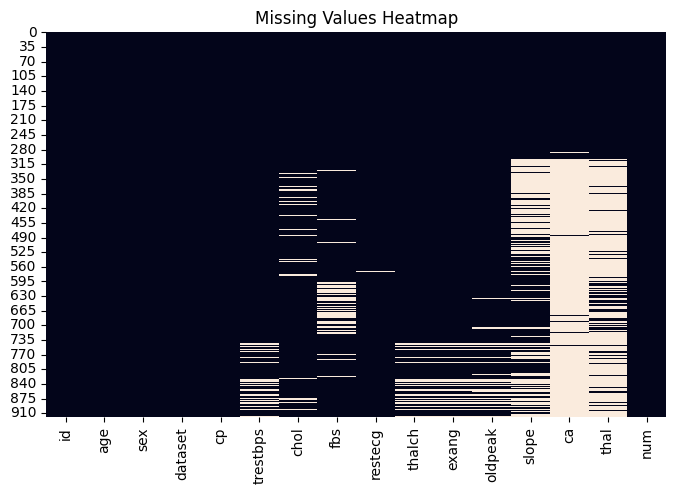

In [ ]:
plt.figure(figsize=(8, 5))
sns.heatmap(heart_disease_uci.isnull(), cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

Numerical Columns

In [ ]:
numerical_cols = heart_disease_uci.select_dtypes(include=["int64", "float64"]).columns
print("NUMERICAL COLUMNS:")
print(numerical_cols)
print("Numerical Columns:", list(numerical_cols))


NUMERICAL COLUMNS:
Index(['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num'], dtype='object')
Numerical Columns: ['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']


Categorical Columns

In [ ]:
categorical_columns = heart_disease_uci.select_dtypes(include=["object" , "category"]).columns
print("CATEGORICAL COLUMNS:")
print(categorical_columns)
print("Categorical Columns:", list(categorical_columns))


CATEGORICAL COLUMNS:
Index(['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal'], dtype='object')
Categorical Columns: ['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [ ]:
heart_disease_uci.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [ ]:
print("Unique Value Analysis For Heart Disease UCI Dataset:")
print("=" * 60)

for col in heart_disease_uci.columns:
    print(f"\n Column: {col}")
    print(f"Unique Values Count: {heart_disease_uci[col].nunique()}")

    if heart_disease_uci[col].nunique() < 10:
        print(f"Unique Values: {heart_disease_uci[col].unique()}")

    print("-"*60)


Unique Value Analysis For Heart Disease UCI Dataset:

 Column: id
Unique Values Count: 920
------------------------------------------------------------

 Column: age
Unique Values Count: 50
------------------------------------------------------------

 Column: sex
Unique Values Count: 2
Unique Values: ['Male' 'Female']
------------------------------------------------------------

 Column: dataset
Unique Values Count: 4
Unique Values: ['Cleveland' 'Hungary' 'Switzerland' 'VA Long Beach']
------------------------------------------------------------

 Column: cp
Unique Values Count: 4
Unique Values: ['typical angina' 'asymptomatic' 'non-anginal' 'atypical angina']
------------------------------------------------------------

 Column: trestbps
Unique Values Count: 61
------------------------------------------------------------

 Column: chol
Unique Values Count: 217
------------------------------------------------------------

 Column: fbs
Unique Values Count: 2
Unique Values: [True False 

**Analyzing Missing Values**

Missing values before handling

In [ ]:
print(heart_disease_uci[['trestbps','chol','fbs','thalch','restecg','exang','oldpeak','slope','ca','thal']].isnull().sum())

trestbps     59
chol         30
fbs          90
thalch       55
restecg       2
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64


Visualize missing values


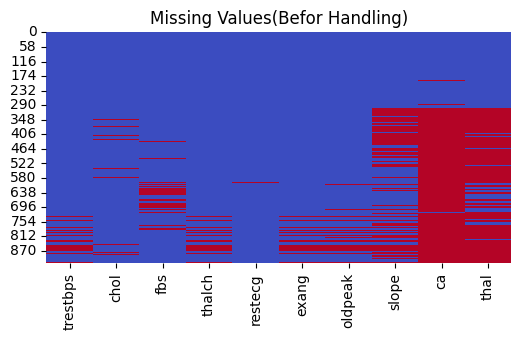

In [ ]:
plt.figure(figsize=(6,3))
sns.heatmap(heart_disease_uci[['trestbps','chol','fbs','thalch','restecg','exang','oldpeak','slope','ca','thal']].isnull(), cbar=False, cmap='coolwarm' )
plt.title('Missing Values(Befor Handling)')
plt.show()

 **Missing values represent by bar plot**

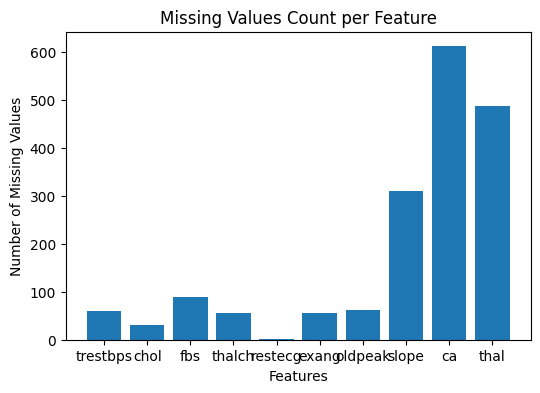

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(heart_disease_uci[['trestbps','chol','fbs','thalch','restecg','exang','oldpeak','slope','ca','thal']].isnull().sum().index, heart_disease_uci[['trestbps','chol','fbs','thalch','restecg','exang','oldpeak','slope','ca','thal']].isnull().sum().values)
plt.title("Missing Values Count per Feature")
plt.ylabel("Number of Missing Values")
plt.xlabel("Features")
plt.show()


Explore Distributions (Before Handling)

**trestbps (Resting BP) [Numerical]**

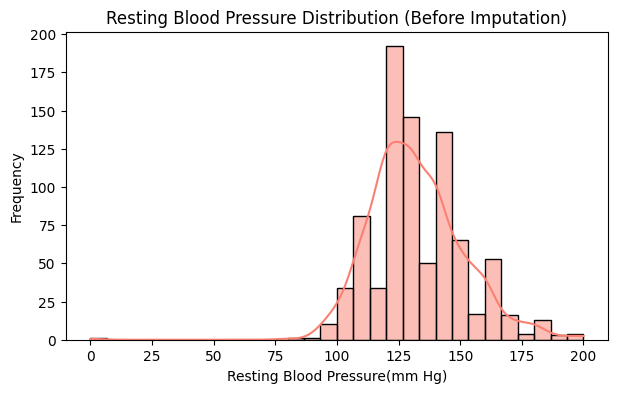

Skewness of trestbps: 0.21333446967212508


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(heart_disease_uci['trestbps'], bins=30, kde=True, color='salmon')
plt.title('Resting Blood Pressure Distribution (Before Imputation)')
plt.xlabel('Resting Blood Pressure(mm Hg)')
plt.ylabel('Frequency')
plt.show()

print("Skewness of trestbps:", heart_disease_uci['trestbps'].skew())


**Oldpeak[Numerical]**

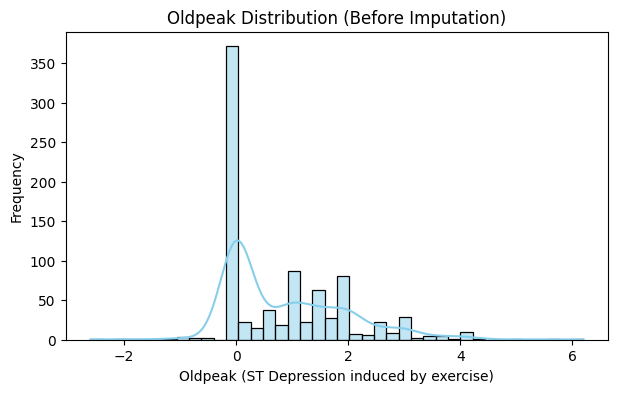

Skewness of Oldpeak: 1.0414266146339854


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(heart_disease_uci['oldpeak'], bins=40, kde=True, color='skyblue')
plt.title("Oldpeak Distribution (Before Imputation)")
plt.xlabel("Oldpeak (ST Depression induced by exercise)")
plt.ylabel("Frequency")
plt.show()

print("Skewness of Oldpeak:", heart_disease_uci['oldpeak'].skew())

**Sex(Male/Female)  [Categorical]**

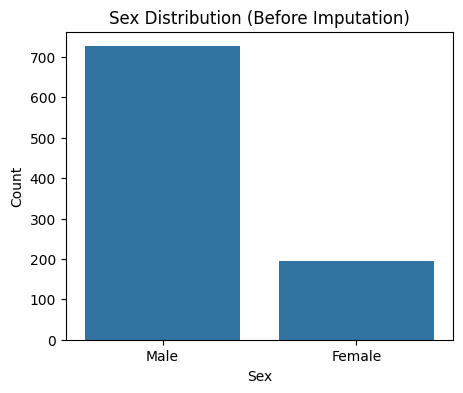

In [ ]:
plt.figure(figsize=(5,4))
sns.countplot(x='sex', data=heart_disease_uci)
plt.title("Sex Distribution (Before Imputation)")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

**cp(Chest pain type) [Categorical]**

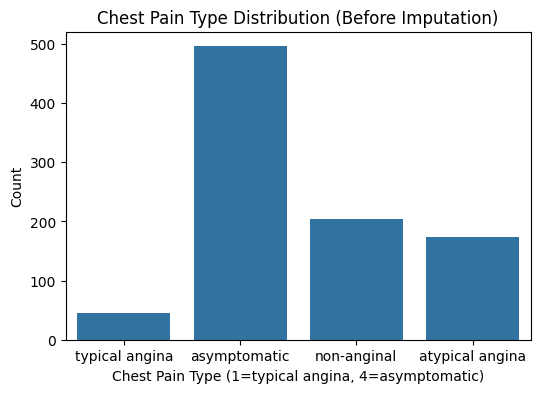

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='cp', data=heart_disease_uci)
plt.title("Chest Pain Type Distribution (Before Imputation)")
plt.xlabel("Chest Pain Type (1=typical angina, 4=asymptomatic)")
plt.ylabel("Count")
plt.show()


In [ ]:
heart_disease_uci['ca'].head()

,ca
0,0.0
1,3.0
2,2.0
3,0.0
4,0.0


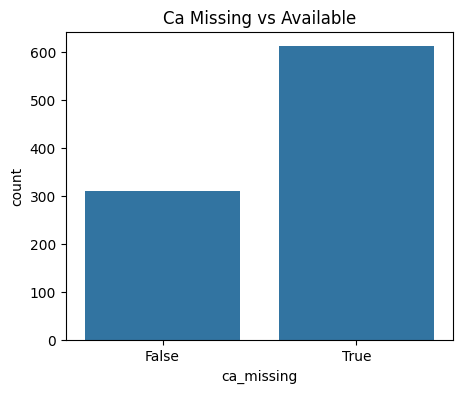

In [ ]:
plt.figure(figsize=(5,4))
heart_disease_uci['ca_missing'] = heart_disease_uci['ca'].isnull()
sns.countplot(x='ca_missing', data=heart_disease_uci)
plt.title("Ca Missing vs Available")
plt.show()

In [ ]:
heart_disease_uci['ca_missing'].tail()

,ca_missing
915,True
916,True
917,True
918,True
919,True


In [ ]:
heart_disease_uci['thal'].head()

,thal
0,fixed defect
1,normal
2,reversable defect
3,normal
4,normal


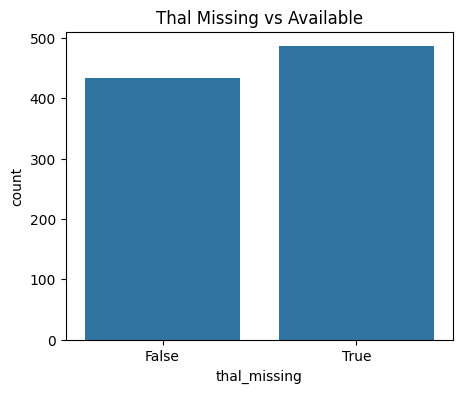

In [ ]:
plt.figure(figsize=(5,4))
heart_disease_uci['thal_missing'] = heart_disease_uci['thal'].isnull()
sns.countplot(x='thal_missing', data=heart_disease_uci)
plt.title("Thal Missing vs Available")
plt.show()

In [ ]:
heart_disease_uci['thal_missing'].tail()

,thal_missing
915,True
916,True
917,False
918,True
919,True


In [ ]:
heart_disease_uci['slope'].head()

,slope
0,downsloping
1,flat
2,flat
3,downsloping
4,upsloping


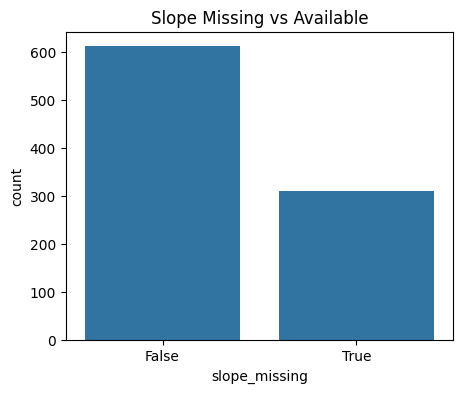

In [ ]:
plt.figure(figsize=(5,4))
heart_disease_uci['slope_missing'] = heart_disease_uci['slope'].isnull()
sns.countplot(x='slope_missing', data=heart_disease_uci)
plt.title("Slope Missing vs Available")
plt.show()

In [ ]:
heart_disease_uci['slope_missing'].tail()

,slope_missing
915,True
916,True
917,True
918,True
919,True


*Columns with missing values

Numerical Columns

If only few missing values → fill with median (median is safer than mean due to outliers)**


In [ ]:
heart_disease_uci['trestbps'].fillna(heart_disease_uci['trestbps'].median(), inplace=True)
heart_disease_uci['chol'].fillna(heart_disease_uci['chol'].median(), inplace=True)
heart_disease_uci['thalch'].fillna(heart_disease_uci['thalch'].median(), inplace=True)
heart_disease_uci['oldpeak'].fillna(heart_disease_uci['oldpeak'].median(), inplace=True)

 # categorical columns → fill with mode.
heart_disease_uci['restecg'].fillna(heart_disease_uci['restecg'].mode()[0], inplace=True)
heart_disease_uci['exang'].fillna(heart_disease_uci['exang'].mode()[0], inplace=True)
heart_disease_uci['fbs'].fillna(heart_disease_uci['fbs'].mode()[0], inplace=True)


/tmp/ipython-input-2012293877.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['trestbps'].fillna(heart_disease_uci['trestbps'].median(), inplace=True)
/tmp/ipython-input-2012293877.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df

In [ ]:
#medium missing values →Fill with mode
heart_disease_uci['slope'].fillna(heart_disease_uci['slope'].mode()[0], inplace=True)

/tmp/ipython-input-2983708201.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['slope'].fillna(heart_disease_uci['slope'].mode()[0], inplace=True)


In [ ]:
# high missing values →Fill with mode
heart_disease_uci['ca'].fillna(heart_disease_uci['ca'].mode()[0], inplace=True)
heart_disease_uci['thal'].fillna(heart_disease_uci['thal'].mode()[0], inplace=True)


/tmp/ipython-input-2219623833.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['ca'].fillna(heart_disease_uci['ca'].mode()[0], inplace=True)
/tmp/ipython-input-2219623833.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].metho

In [ ]:
print(heart_disease_uci.isnull().sum())

id               0
age              0
sex              0
dataset          0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalch           0
exang            0
oldpeak          0
slope            0
ca               0
thal             0
num              0
ca_missing       0
thal_missing     0
slope_missing    0
dtype: int64


In [ ]:
heart_disease_uci.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,ca_missing,thal_missing,slope_missing
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,False,False,False
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,False,False,False
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,False,False,False
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,False,False,False
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,False,False,False


Lambda Functions

Missing values handel by grouping

In [ ]:
# Fill 'thal missing values with group_wise mode.
heart_disease_uci['thal'] = heart_disease_uci.groupby(['sex', 'cp'])['thal'].transform (lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Unknown'))
heart_disease_uci['thal'].fillna(heart_disease_uci['thal'].mode()[0], inplace=True)

/tmp/ipython-input-69797544.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['thal'].fillna(heart_disease_uci['thal'].mode()[0], inplace=True)


In [ ]:
# Fill 'slope' missing values with group_wise mode.
heart_disease_uci['slope'] = heart_disease_uci.groupby(['sex', 'cp'])['slope'].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Unknown'))
heart_disease_uci['slope'].fillna(heart_disease_uci['slope'].mode()[0], inplace=True)

/tmp/ipython-input-400297507.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['slope'].fillna(heart_disease_uci['slope'].mode()[0], inplace=True)


In [ ]:
heart_disease_uci['chol'] = heart_disease_uci.groupby(['sex', 'cp'])['chol'].transform(lambda x: x.fillna(x.median()))
heart_disease_uci['chol'].fillna(heart_disease_uci['chol'].median(), inplace=True)


/tmp/ipython-input-515426265.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['chol'].fillna(heart_disease_uci['chol'].median(), inplace=True)


In [ ]:
heart_disease_uci['chol'] = heart_disease_uci['chol'].apply(lambda x: np.nan if x <= 0 else x)
heart_disease_uci['chol'].fillna(heart_disease_uci['chol'].median(), inplace=True)


/tmp/ipython-input-451608515.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_disease_uci['chol'].fillna(heart_disease_uci['chol'].median(), inplace=True)


In [ ]:
heart_disease_uci['chol'] = heart_disease_uci['chol'].apply(lambda x: np.nan if pd.isnull(x) or x <= 0 or x > 600 else x).fillna(heart_disease_uci['chol'].median())


In [ ]:
heart_disease_uci['chol_level'] = pd.cut(
    heart_disease_uci['chol'],
    bins=[0, 200, 240, 600],
    labels=['Normal', 'Borderline', 'High']
)

In [ ]:
print("Missing values after final fix:")
print(heart_disease_uci[['chol', 'chol_level']].isnull().sum())

Missing values after final fix:
chol          0
chol_level    0
dtype: int64


In [ ]:
heart_disease_uci.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,ca_missing,thal_missing,slope_missing,chol_level
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,False,False,False,Borderline
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,False,False,False,High
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,False,False,False,Borderline
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,False,False,False,High
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,False,False,False,Borderline


In [ ]:
missing = heart_disease_uci.isnull().sum()
print("Missing Values :")
print(missing)

Missing Values :
id               0
age              0
sex              0
dataset          0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalch           0
exang            0
oldpeak          0
slope            0
ca               0
thal             0
num              0
ca_missing       0
thal_missing     0
slope_missing    0
chol_level       0
dtype: int64


# Analysing After Handling Missing Values:

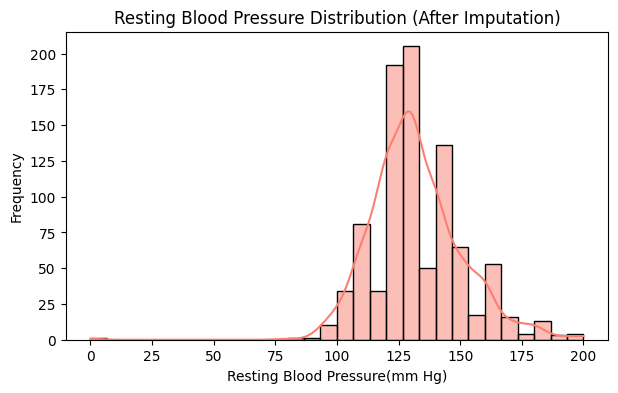

Skewness of trestbps: 0.24241673556477622


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(heart_disease_uci['trestbps'], bins=30, kde=True, color='salmon')
plt.title('Resting Blood Pressure Distribution (After Imputation)')
plt.xlabel('Resting Blood Pressure(mm Hg)')
plt.ylabel('Frequency')
plt.show()

print("Skewness of trestbps:", heart_disease_uci['trestbps'].skew())


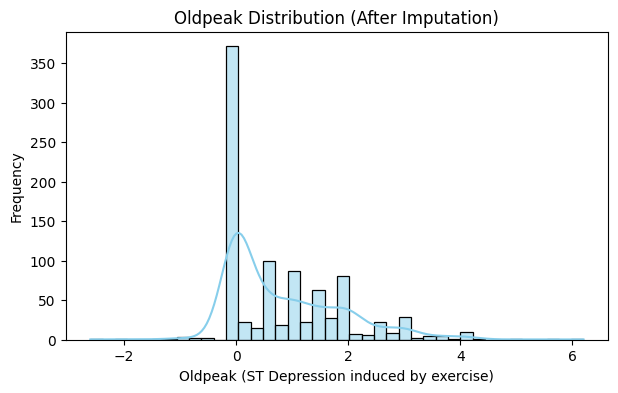

Skewness of Oldpeak: 1.1347025952263665


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(heart_disease_uci['oldpeak'], bins=40, kde=True, color='skyblue')
plt.title("Oldpeak Distribution (After Imputation)")
plt.xlabel("Oldpeak (ST Depression induced by exercise)")
plt.ylabel("Frequency")
plt.show()

print("Skewness of Oldpeak:", heart_disease_uci['oldpeak'].skew())

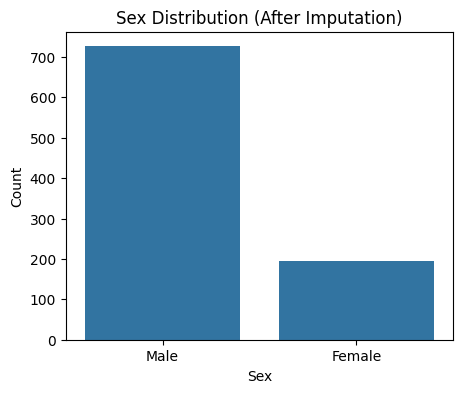

In [ ]:
plt.figure(figsize=(5,4))
sns.countplot(x='sex', data=heart_disease_uci)
plt.title("Sex Distribution (After Imputation)")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

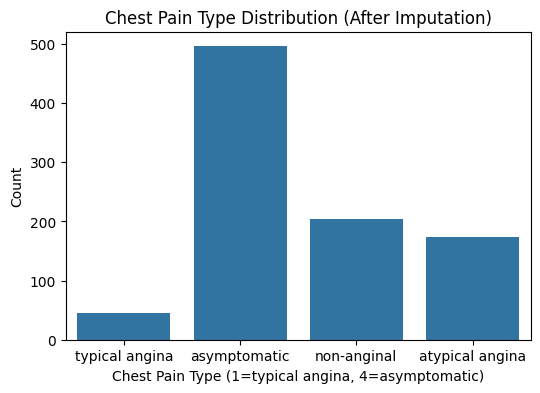

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='cp', data=heart_disease_uci)
plt.title("Chest Pain Type Distribution (After Imputation)")
plt.xlabel("Chest Pain Type (1=typical angina, 4=asymptomatic)")
plt.ylabel("Count")
plt.show()

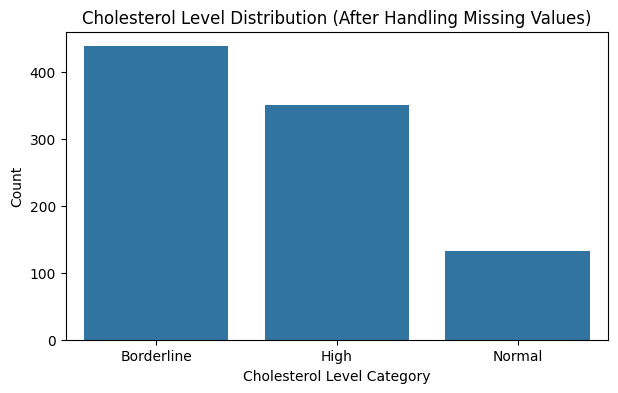

In [ ]:
plt.figure(figsize=(7,4))
sns.countplot(x='chol_level',data=heart_disease_uci,order=heart_disease_uci['chol_level'].value_counts().index)
plt.title("Cholesterol Level Distribution (After Handling Missing Values)")
plt.xlabel("Cholesterol Level Category")
plt.ylabel("Count")
plt.show()


# Feature Engineering

In [ ]:
heart_disease_uci['AgeGroup'] = pd.cut(
    heart_disease_uci['age'],
    bins=[0, 40, 60, 90],
    labels=['Young', 'Middle_aged', 'Senior' ]
)

heart_disease_uci['IsSenoir'] = (heart_disease_uci['age'] > 60)

In [ ]:
heart_disease_uci.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,...,slope,ca,thal,num,ca_missing,thal_missing,slope_missing,chol_level,AgeGroup,IsSenoir
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,...,downsloping,0.0,fixed defect,0,False,False,False,Borderline,Senior,True
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,...,flat,3.0,normal,2,False,False,False,High,Senior,True
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,...,flat,2.0,reversable defect,1,False,False,False,Borderline,Senior,True
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,...,downsloping,0.0,normal,0,False,False,False,High,Young,False
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,...,upsloping,0.0,normal,0,False,False,False,Borderline,Middle_aged,False


In [ ]:
#Title-like Feature Creation for Heart Disease dataset

#  Combine 'sex' + 'dataset' to make a new column "Title"
#  Male + Cleveland → Male_Cleveland
heart_disease_uci['Title'] = heart_disease_uci['sex']+ "_" + heart_disease_uci['dataset']
#Check frequency of each Title (for balancing categories)
title_counts = heart_disease_uci['Title'].value_counts()
#Define 'Rare' category
# If a Title appears less than 20 times, replace it with 'Rare'
rare_titles = title_counts[title_counts < 20].index
heart_disease_uci['Title'] = heart_disease_uci['Title'].replace(rare_titles, 'Rare')

In [ ]:
heart_disease_uci.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,...,ca,thal,num,ca_missing,thal_missing,slope_missing,chol_level,AgeGroup,IsSenoir,Title
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,...,0.0,fixed defect,0,False,False,False,Borderline,Senior,True,Male_Cleveland
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,...,3.0,normal,2,False,False,False,High,Senior,True,Male_Cleveland
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,...,2.0,reversable defect,1,False,False,False,Borderline,Senior,True,Male_Cleveland
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,...,0.0,normal,0,False,False,False,High,Young,False,Male_Cleveland
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,...,0.0,normal,0,False,False,False,Borderline,Middle_aged,False,Female_Cleveland


# Visual EDA

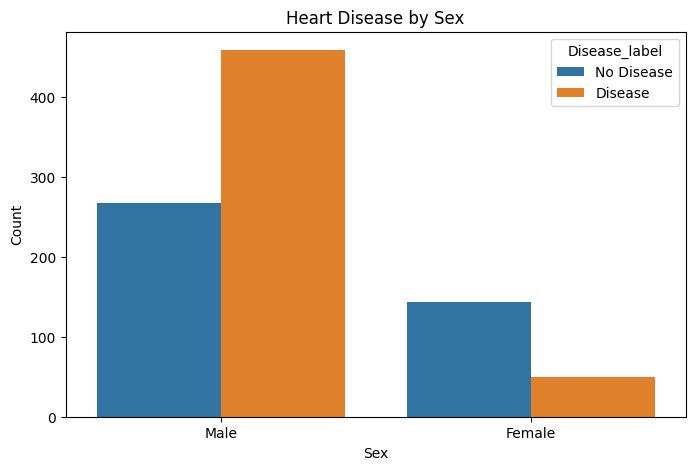

In [ ]:
heart_disease_uci['Disease_label'] = heart_disease_uci['num'].map(lambda x: 'No Disease' if x == 0 else 'Disease')
plt.figure(figsize=(8,5))
sns.countplot(x='sex', hue='Disease_label', data=heart_disease_uci)            # 0 = No Disease, 1/2/3/4 = Disease
plt.title('Heart Disease by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()

/tmp/ipython-input-4653273.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='cp', y='Disease_binary', data=heart_disease_uci, estimator=np.mean, ci=None)


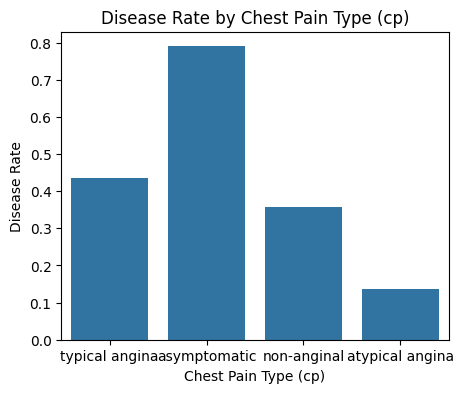

In [ ]:
heart_disease_uci['Disease_binary'] = (heart_disease_uci['num'] > 0)
plt.figure(figsize=(5,4))                                                            # 0 = No disease , 1 = disease
sns.barplot(x='cp', y='Disease_binary', data=heart_disease_uci, estimator=np.mean, ci=None)
plt.title('Disease Rate by Chest Pain Type (cp)')
plt.ylabel('Disease Rate')
plt.xlabel('Chest Pain Type (cp)')
plt.show()

Age distribution by Disease presence Represent By Kernel Density Estimation Plot:

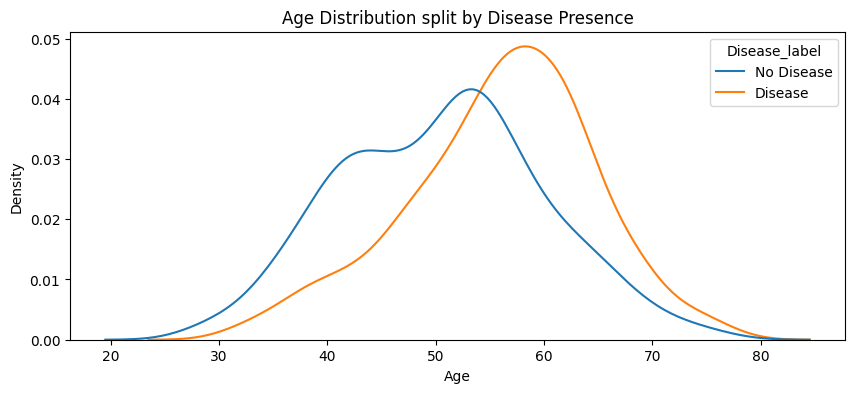

In [ ]:
plt.figure(figsize=(10,4))
sns.kdeplot(data=heart_disease_uci, x='age', hue='Disease_label', common_norm=False)

plt.title('Age Distribution split by Disease Presence')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

# Age distribution by Disease presence Represent By Pie Chart:

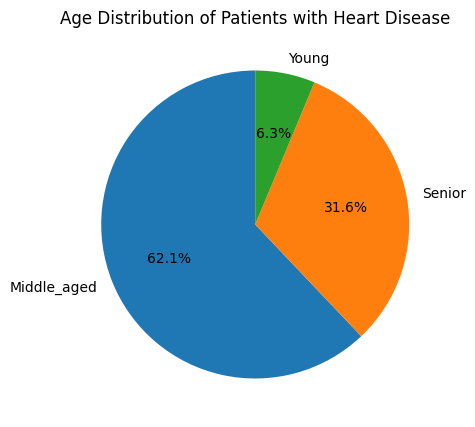

In [ ]:
age_disease_counts = heart_disease_uci[heart_disease_uci['Disease_label']=='Disease']['AgeGroup'].value_counts()
plt.figure(figsize=(5,5))
plt.pie(age_disease_counts, labels=age_disease_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Age Distribution of Patients with Heart Disease')
plt.show()

/tmp/ipython-input-1584876468.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='dataset', y='Disease_binary', data=heart_disease_uci, estimator=np.mean, ci=None)


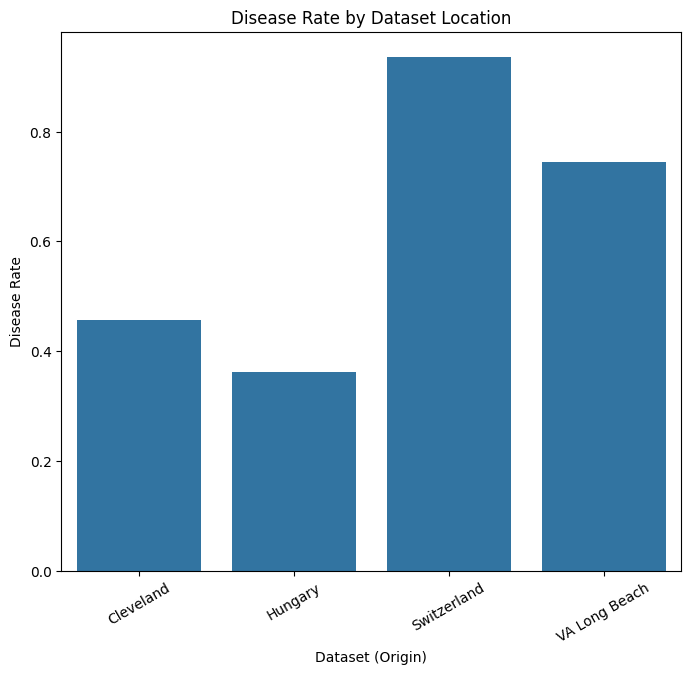

In [ ]:
#disease rate by dataset:
plt.figure(figsize=(8,7))
sns.barplot(x='dataset', y='Disease_binary', data=heart_disease_uci, estimator=np.mean, ci=None)
plt.title('Disease Rate by Dataset Location')
plt.ylabel('Disease Rate')
plt.xlabel('Dataset (Origin)')
plt.xticks(rotation=30)
plt.show()


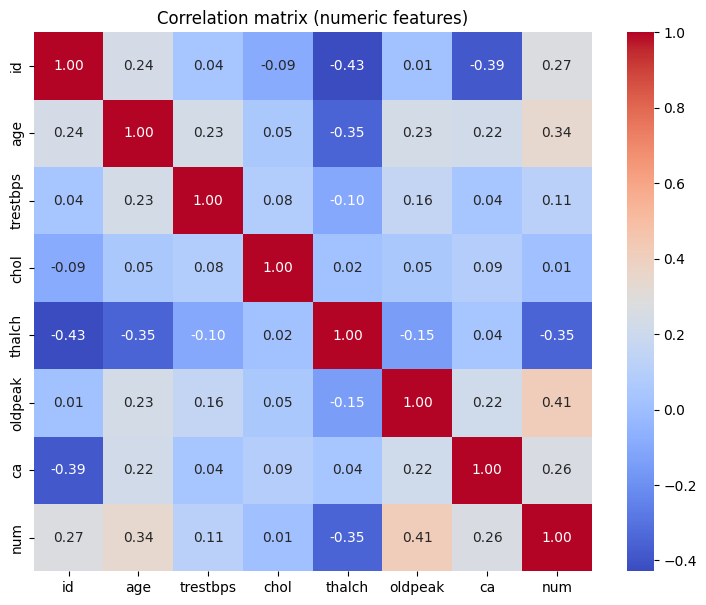

In [ ]:
#Correlation heatmap (numeric features):
#Select only numeric columns from dataset:
num_cols = heart_disease_uci.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(9,7))
sns.heatmap(heart_disease_uci[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation matrix (numeric features)')
plt.show()

# Analysing Questions

Q 1. What is the distribution of chest pain types?

In [ ]:
if 'cp' in heart_disease_uci.columns:
  cp_distribution = heart_disease_uci['cp'].value_counts()
  print("Chest Pian Type Distribution:")
  print(cp_distribution)

Chest Pian Type Distribution:
cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64


 Q 2. What is the distribution of patients by sex (Male/Female)?

In [ ]:
if 'sex' in heart_disease_uci.columns:
  sex_distribution = heart_disease_uci['sex'].value_counts()
  print("Distribution of Patients by Sex")
  print(sex_distribution)

Distribution of Patients by Sex
sex
Male      726
Female    194
Name: count, dtype: int64


Q 3. What is the relationship between exercise-induced angina (exang) and disease presence (num)?

In [ ]:
if set(['exang','num']).issubset(heart_disease_uci.columns):
   relation = pd.crosstab(heart_disease_uci['exang'], heart_disease_uci['num'])
print("Relationship Between Exercise_Induced Angina (exang) & Disease Presence(num): ")
print(relation)

Relationship Between Exercise_Induced Angina (exang) & Disease Presence(num): 
num      0    1   2   3   4
exang                      
False  356  120  51  43  13
True    55  145  58  64  15


Q 4. How many patients fall into each disease category (num values 0–4)?

In [ ]:
if 'num' in heart_disease_uci.columns:
    disease_counts = heart_disease_uci['num'].value_counts().sort_index()

    print("Number of patients in each disease category (0–4):")
    print(disease_counts)


Number of patients in each disease category (0–4):
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


Q 5. What is the average resting blood pressure (trestbps) and cholesterol (chol)?

In [ ]:
avg_trestbps = heart_disease_uci['trestbps'].mean()
avg_chol = heart_disease_uci['chol'].mean()

print("Average Resting Blood Pressure (trestbps):", round(avg_trestbps,2))
print("Average Cholesterol (chol):", round(avg_chol,2))

Average Resting Blood Pressure (trestbps): 132.0
Average Cholesterol (chol): 241.19


Q 6.  How does the maximum heart rate (thalach) differ between diseased and non-diseased patients?

In [ ]:
thalch_compare = heart_disease_uci.groupby('num')['thalch'].mean()

print(thalch_compare)

num
0    148.372263
1    131.475472
2    129.394495
3    122.869159
4    128.714286
Name: thalch, dtype: float64


# Conclusion (Heart Disease Dataset EDA)

Age and Disease: The prevalence of heart disease increases with age, especially in patients over 50, suggesting age is a strong risk factor.

Sex Distribution: Male patients are more frequently affected by heart disease compared to females, which aligns with known medical literature.

Chest Pain Types (cp): Patients with asymptomatic chest pain show a much higher association with heart disease, whereas typical angina is more common among non-diseased individuals.

Resting Blood Pressure & Cholesterol: Average resting blood pressure and cholesterol levels are slightly elevated among diseased patients, reinforcing the importance of lifestyle and diet in prevention.

Maximum Heart Rate (thalch): Non-diseased patients achieve a significantly higher maximum heart rate during exercise, while diseased patients tend to have lower values—indicating reduced exercise tolerance.

Exercise-Induced Angina (exang): Patients who experience angina during exercise are more likely to have heart disease, making this a useful predictive feature.

Electrocardiogram (restecg) and Slope: Certain abnormal ECG patterns and flat/downsloping ST segments are more frequent among diseased patients.

Data Quality: Several features (e.g., thal, slope, ca) contained missing values, which were handled using group-wise imputation. This ensured the analysis remained robust without discarding valuable records.


Overall, the analysis highlights clear differences between diseased and non-diseased patients in terms of age, chest pain, heart rate, and exercise response. These findings not only demonstrate the predictive potential of the dataset but also reflect real-world clinical patterns, making this project both data-driven and medically meaningful.

This project shows how EDA is a powerful first step—from detecting missing values to uncovering risk factors—and lays the foundation for predictive modeling in heart disease detection.